# VolleyMap
With this project, we aim to identify and locate the referee area within frames captured from volleyball games using a standard lateral camera setup.

The objective of this work is to perform all processing without involving any trained AI models, relying instead on traditional signal processing techniques.

After exploring several alternative approaches including direct referee detection based on uniform color and shape recognition, immediate line detection for court boundaries, and other direct object identification methods, we discovered that the most reliable and informative feature is the court's color composition.

**Initial Approaches Evaluated:**
- **Direct referee detection**: Attempted to identify referees by analyzing typical uniform colors (black/white stripes) and human silhouette shapes
- **Immediate line recognition**: Applied line detection algorithms directly to identify court boundaries and net structures
- **Object-specific detection**: Targeted individual elements without establishing spatial context

Through experimentation, we determined that the volleyball court's distinct color characteristics provide the most stable foundation for hierarchical detection. The court's consistent color properties across different frames make it an ideal anchor point for establishing spatial relationships with other game elements.

This insight led us to adopt a court-first strategy: we prioritize court segmentation and identification as the foundation, then use the established court boundaries as reference points to locate the net and define the referee area. This hierarchical approach leverages the court's reliability as a spatial anchor, significantly improving the robustness and accuracy of subsequent object detection steps.

## Our final approach

Our approach follows a hierarchical detection strategy: we first segment and identify the volleyball court boundaries using K-means clustering, then locate the net position through vertical line detection, and finally determine the referee's area based on these reference points. This sequential method simplifies the detection process by establishing clear spatial relationships between court elements and reduces computational complexity.

Once the referee region is isolated, our pipeline can seamlessly integrate with existing computer vision models specifically trained for referee gesture recognition, enabling automated interpretation of officiating signals from the extracted referee imagery.

Since we successfully identify both the playing court and the net to reach our final objective of referee area detection, these submodules can be used independently for other applications, such as court analytics, player tracking systems, or broadcast enhancement tools.

# Setup

### Import Libraries

In [130]:
import cv2
import numpy as np
from functools import reduce

from matplotlib import pyplot as plt  # For plotting inline images

# Set default figure size for all plots
import pylab
pylab.rcParams['figure.figsize'] = (14.0, 6.0)

### Constants

We have chosen 3 clusters to segment the image based on the visual characteristics of the volleyball courts in our test dataset. This parameter can be easily adjusted to achieve optimal results once you understand the specific color composition and lighting conditions of the target court environment.

The number of clusters should be selected based on the distinct color regions present in your volleyball court setup:
- **2 clusters**: For courts with simple color schemes (e.g., single-color court vs. background)
- **3 clusters**: For typical indoor courts with court surface, surrounding area, and background elements
- **4+ clusters**: For complex environments with multiple distinct color regions or varying lighting conditions

**Suggestion**: Analyze your target court's color histogram and adjust `N_CLUSTERS` accordingly for optimal segmentation performance.

In [131]:
# Set the path to the input image and the number of clusters for K-means segmentation.

# Path to the volleyball game frame to be processed.
IMAGE_PATH = 'data/duca.png'

# Number of color clusters to segment the court
N_CLUSTERS = 3

## Image preparation

We begin by loading the input image and enhancing its saturation to improve color differentiation, as our methodology relies on clustering pixels based on their color characteristics. This preprocessing step is crucial for achieving better segmentation accuracy in the subsequent K-means clustering algorithm.

**Saturation Enhancement Process:**
- Convert the image from BGR to HSV color space for targeted manipulation
- Multiply the saturation (S) channel by 2.0, effectively doubling the color intensity
- Clip values to the valid range [0, 255] to prevent overflow artifacts
- Convert back to RGB for further processing

This enhancement amplifies the distinction between different court elements (playing surface, surrounding areas, background), making the color-based clustering more robust and improving the separability of court regions from non-court areas. The increased saturation particularly helps distinguish subtle color variations that might be overlooked in the original image, leading to more accurate court boundary detection.

In [132]:
# Load the image and convert it to RGB
image = cv2.imread(IMAGE_PATH)
original_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert to HSV for saturation enhancement
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Enhance saturation by multiplying the S channel
h, s, v = cv2.split(hsv)
s = cv2.multiply(s, 2.0)  # Increase saturation by 100%
s = np.clip(s, 0, 255).astype(np.uint8)  # Ensure values stay within valid range

# Merge channels back and convert to RGB
enhanced_hsv = cv2.merge([h, s, v])
enhanced_rgb = cv2.cvtColor(enhanced_hsv, cv2.COLOR_HSV2RGB)


### Visual Comparison: Original vs. Enhanced Saturation

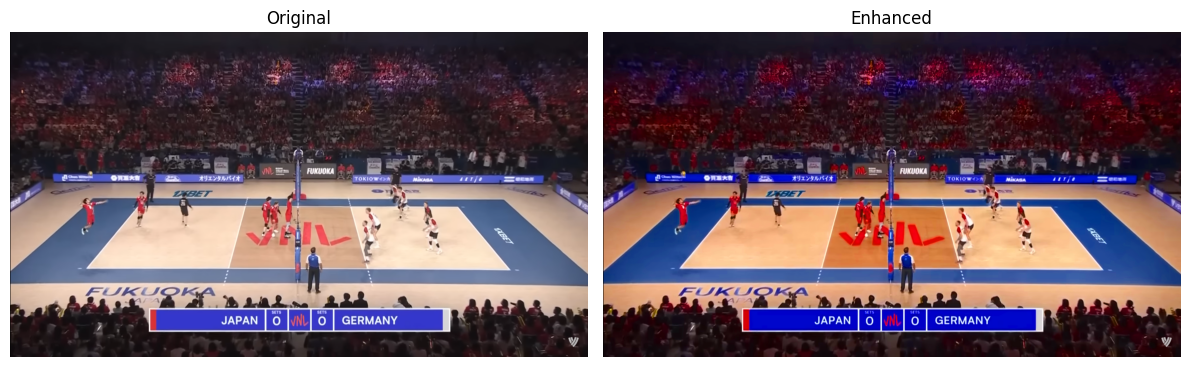

In [133]:
# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Display original_rgb
axes[0].imshow(original_rgb)
axes[0].set_title('Original')
axes[0].axis('off')

# Display enhanced_rgb
axes[1].imshow(enhanced_rgb)
axes[1].set_title('Enhanced')
axes[1].axis('off')

# Show the figure
plt.tight_layout()
plt.show()

# Court recognition

As the foundation of our hierarchical detection strategy, this section focuses on recognizing and segmenting the volleyball court within the input image using traditional computer vision techniques.

## K\-means

To accomplish this, we employ a color-based K-means clustering approach to analyze the court's distinct visual characteristics. Our methodology involves partitioning the enhanced image into three distinct color clusters to capture the primary color regions present in the scene (court surface, surrounding areas, and background elements).

In [134]:
# Flatten the dimensions of the image for each channel for easier processing
# from [height, width, 3 (channels RGB)] (3 matrices) to [height * width, 3] (3 vectors)
pixels = enhanced_rgb.reshape((-1, 3)).astype(np.float32)

# Define the stop criteria for K-means:
# either at 100 max iterations or when the 1.0 (epsilon) accuracy is reached
criteria = (cv2.TERM_CRITERIA_MAX_ITER + cv2.TERM_CRITERIA_EPS, 100, 1.0)

# Apply K-means clustering with the specified number of clusters
# Parameters: data, k, bestLabels (none), criteria, attempts, flags (ten attempts, random centers)
_, labels, centers = cv2.kmeans(pixels, N_CLUSTERS, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# Reshape the labels back to the original image dimensions
# This creates a map where each pixel is assigned to a cluster (0, 1, or 2)
labels_map = labels.reshape(enhanced_rgb.shape[:2])


In the following code block, we visualize the results of the K-means clustering algorithm.

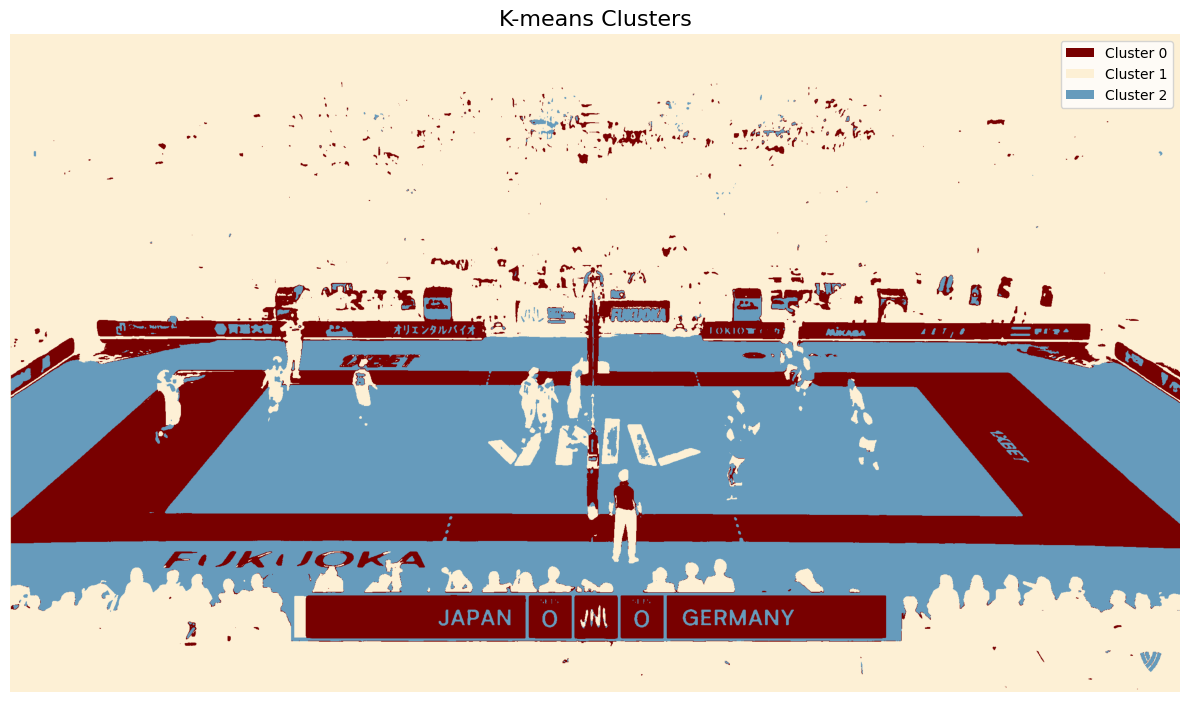

In [135]:
# Create a colored image showing all clusters
colored_clusters = np.zeros((labels_map.shape[0], labels_map.shape[1], 3), dtype=np.uint8)

# Define colors for each cluster (RGB format)
colors = [
    [120, 0, 0],        # Dark red for Cluster 0
    [253, 240, 213],    # Light beige for Cluster 1
    [102, 155, 188]     # Blue for Cluster 2
]

# Apply colors to each cluster
for i in range(N_CLUSTERS):
    mask = labels_map == i
    colored_clusters[mask] = colors[i]

# Create the plot with legend
fig, ax = plt.subplots(1, 1, figsize=(12, 8))
ax.imshow(colored_clusters)
ax.set_title('K-means Clusters', fontsize=16)
ax.axis('off')

# Create legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=np.array(colors[i])/255.0, label=f'Cluster {i}') 
                   for i in range(N_CLUSTERS)]
ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()

## Connected Components

### Functions definition

The following functions will be used in subsequent code blocks.

In [136]:
def apply_hough(image):
    """
    Apply Hough line detection and morphological operations to detect and enhance lines.
    
    Parameters:
    -----------
    image : numpy.ndarray
        Input binary image (grayscale, single channel) for line detection
        
    Returns:
    --------
    numpy.ndarray
        Binary image with detected lines enhanced using morphological closing
        
    Description:
    ------------
    This function performs the following steps:
    1. Detects lines using Probabilistic Hough Line Transform with optimized parameters
    2. Draws detected lines on a blank canvas with white color and 2-pixel thickness
    3. Converts the colored line image back to grayscale binary format
    4. Applies horizontal morphological closing to connect nearby line segments and fill gaps
    
    The function is particularly effective for detecting horizontal structures and 
    connecting fragmented line segments through morphological operations.
    """
    lines = cv2.HoughLinesP(image, 1, np.pi / 180, threshold=10, minLineLength=5, maxLineGap=200)
    h, w = image.shape
    lines_img = np.zeros((h, w, 3), dtype=np.uint8)

    if lines is not None:
        for line in lines:
            x1, y1, x2, y2 = line[0]
            cv2.line(lines_img, (x1, y1), (x2, y2), (255, 255, 255), 2)

    gray = cv2.cvtColor(lines_img, cv2.COLOR_RGB2GRAY)
    _, binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

    # Use horizontal rectangular kernel for connecting horizontal line segments
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (50, 1))
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

    return closed


def fill_contours(mask, contours):
    """
    Fill contours by connecting border points and applying iterative Hough line detection.

    Parameters:
    -----------
    mask : numpy.ndarray
        Input binary mask (single channel, uint8) used as template for output dimensions
    contours : list
        List of contours detected by cv2.findContours, each contour is an array of points
        
    Returns:
    --------
    numpy.ndarray
        Binary mask with filled contours, same dimensions as input mask
        
    Description:
    ------------
    This function performs comprehensive contour filling through:
    1. Drawing contour outlines as thin white lines on a black canvas
    2. Connecting gaps along image borders (top, bottom, left, right edges) 
       by drawing lines between contour points that intersect each border
    3. Applying Hough line detection to enhance and connect line structures
    4. Finding and completely filling the resulting closed contours
    
    The border connection step is crucial for handling contours that extend to image edges,
    ensuring they form closed shapes that can be properly filled. The Hough application
    strengthens weak connections and bridges small gaps in the contour structure.
    """
    contour_img = np.zeros_like(mask)
    cv2.drawContours(contour_img, contours, -1, 255, 1)

    h, w = contour_img.shape

    # Connect gaps on top and bottom borders
    for y in [0, h - 1]:
        row = contour_img[y, :]
        on_indices = np.where(row > 0)[0]
        if len(on_indices) >= 2:
            for i in range(len(on_indices) - 1):
                x1, x2 = on_indices[i], on_indices[i + 1]
                if x2 - x1 > 1:  # Only connect if there's a gap
                    cv2.line(contour_img, (x1, y), (x2, y), 255, 1)

    # Connect gaps on left and right borders
    for x in [0, w - 1]:
        col = contour_img[:, x]
        on_indices = np.where(col > 0)[0]
        if len(on_indices) >= 2:
            for i in range(len(on_indices) - 1):
                y1, y2 = on_indices[i], on_indices[i + 1]
                if y2 - y1 > 1:  # Only connect if there's a gap
                    cv2.line(contour_img, (x, y1), (x, y2), 255, 1)
    
    # Apply Hough line detection for robust line enhancement and gap filling
    closed = apply_hough(contour_img) + contour_img

    # Find final contours and fill them completely
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(mask)
    cv2.drawContours(filled, contours, -1, 255, thickness=cv2.FILLED)
        
    return filled

### Field Identification

For each resulting cluster, we apply a comprehensive preprocessing pipeline:

1. **Noise Reduction**: Horizontal Gaussian blur (151×1 kernel) to eliminate small artifacts like players, equipment, and texture details while preserving major horizontal court structures
2. **Binary Thresholding**: Convert blurred images to clean binary masks using a fixed threshold (127)
3. **Morphological Operations**: 
   - **Opening**: Remove small horizontal noise artifacts using rectangular kernels (50×1)
   - **Closing**: Fill gaps and connect fragmented court boundaries

Subsequently, we identify the largest connected component within each cluster using connected component analysis, as this typically corresponds to the most significant and coherent region of that particular color. This step effectively filters out small scattered pixels and isolated noise regions.



In [137]:
# Initialize lists to store processing results for each cluster
filled_components = []  # Final filled components for comparison
components = []         # Largest connected components (binary masks)
masks = []             # Original cluster masks
binaries = []          # Thresholded binary masks
closeds = []           # Morphologically processed masks

# Process each cluster to find the largest connected component
# This involves preprocessing to remove noise and artifacts, then filling holes
for i in range(N_CLUSTERS):
  
  # Create binary mask for the current cluster (convert boolean to 0-255 range)
  mask = ((labels_map == i).astype(np.uint8)) * 255
  masks.append(mask)
  
  # Apply horizontal Gaussian blur to remove small artifacts
  # Large horizontal kernel (151x1) smooths out noise like players, net details, etc.
  # while preserving major horizontal structures like court boundaries
  blurred = cv2.GaussianBlur(mask, (151, 1), 0)
  
  # Apply binary threshold to create clean binary image
  # Pixels < 127 become 0 (black), >= 127 become 255 (white)
  _, binary = cv2.threshold(blurred, 127, 255, cv2.THRESH_BINARY)
  binaries.append(binary)
  
  # Remove horizontal artifacts using morphological operations
  # Horizontal rectangular kernel (50x1) targets small horizontal noise
  kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (50, 1))
  
  # Opening: erosion followed by dilation - removes small objects
  opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
  
  # Closing: dilation followed by erosion - fills small gaps
  closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)
  closeds.append(closed)
  
  # Find connected components and extract the largest one
  # This identifies separate regions and selects the most significant area
  num_labels, labels_im = cv2.connectedComponents(closed)
  component_mask = np.zeros_like(closed)
  
  if num_labels > 1:  # Ensure we have components beyond background (label 0)
    # Count pixels for each component (excluding background at index 0)
    areas = np.bincount(labels_im.flatten())[1:]
    
    # Find the component with maximum area
    max_label = np.argmax(areas) + 1  # +1 to account for background exclusion
    
    # Create mask containing only the largest component
    component_mask = (labels_im == max_label).astype(np.uint8) * 255
  
  # Store the largest component for later comparison
  components.append(component_mask)
  
  # Find contours of the largest component to prepare for hole filling
  # RETR_EXTERNAL gets only outer contours, ignoring holes
  contours, _ = cv2.findContours(component_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
  
  # Fill any holes within the component using custom fill_contours function
  # This ensures we have solid regions without internal gaps
  filled = fill_contours(component_mask, contours)
  filled_components.append(filled)

### Processing Pipeline Visualization

We can observe how each processing step systematically removes noise and progressively improves the identification of actual court components in the image. This step-by-step visualization demonstrates the effectiveness of our preprocessing pipeline in isolating meaningful structures while eliminating artifacts.

Each transformation reduces noise while preserving essential court geometry, ultimately enabling robust court identification across different lighting conditions and camera perspectives.


Cluster 0 processing steps:


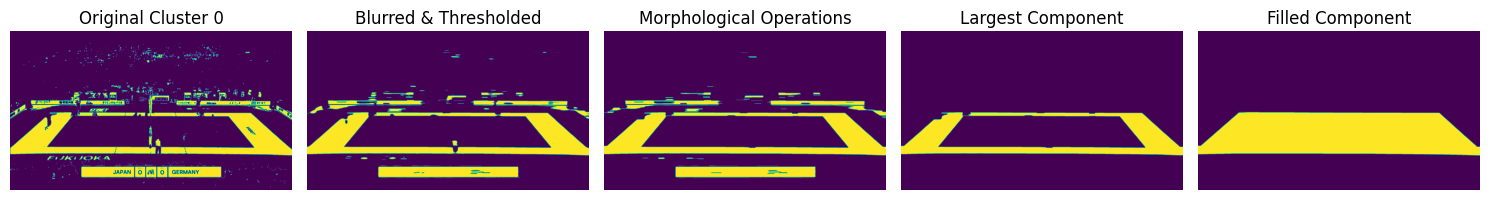


Cluster 1 processing steps:


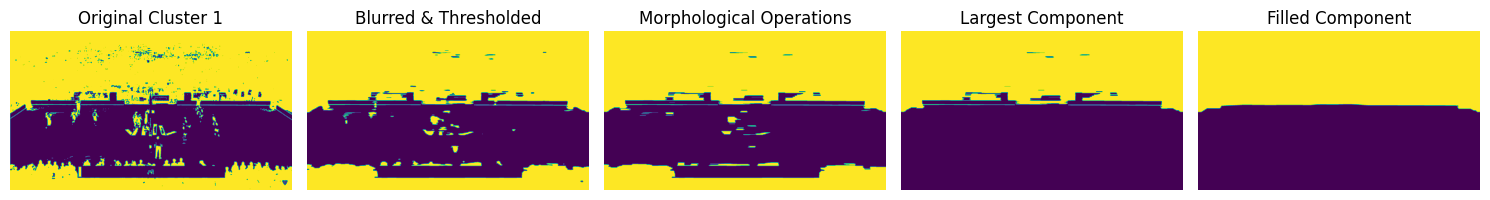


Cluster 2 processing steps:


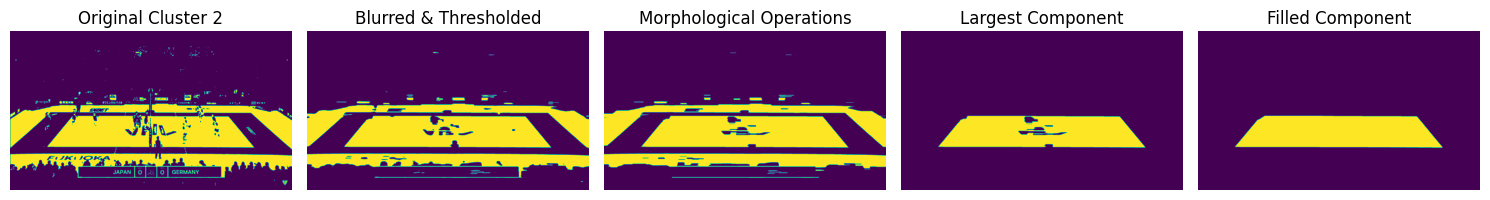

In [138]:
for i in range(N_CLUSTERS):
  print(f"\nCluster {i} processing steps:")

  plt.figure(figsize=(15, 4))
  plt.subplot(1, 5, 1)
  plt.imshow(masks[i])
  plt.title(f'Original Cluster {i}')
  plt.axis('off')

  plt.subplot(1, 5, 2)
  plt.imshow(binaries[i])
  plt.title(f'Blurred & Thresholded')
  plt.axis('off')

  plt.subplot(1, 5, 3)
  plt.imshow(closeds[i])
  plt.title(f'Morphological Operations')
  plt.axis('off')

  plt.subplot(1, 5, 4)
  plt.imshow(components[i])
  plt.title(f'Largest Component')
  plt.axis('off')
  
  plt.subplot(1, 5, 5)
  plt.imshow(filled_components[i])
  plt.title(f'Filled Component')
  plt.axis('off')
  
  plt.tight_layout()
  plt.show()

### Court Selection Algorithm

Finally, we perform a sophisticated comparative analysis of these three primary components to determine which one accurately represents the actual volleyball court area. Our selection criteria include:

- **Hole Detection**: Remove candidates with significant internal holes by checking overlap with other cluster regions (similarity threshold: 90%)
- **Spatial Positioning**: Calculate the center of mass for each valid candidate
- **Distance Metric**: Select the component whose centroid is closest to the expected court center (horizontal center, 2/3 down the image height)

This dual-criteria approach ensures robust identification of the actual volleyball court area while rejecting false positives such as surrounding areas that may appear court-like but contain significant court-shaped holes.

#### Hole Detection Process

More precisely, hole detection is achieved by removing pixels from each component that belong to other clusters, allowing holes that may have been inadvertently filled in previous steps to be properly recognized. For example, the surrounding court area might initially appear as a valid component, but it contains a "court-shaped hole" in its center (the real court).

The hole detection algorithm works as follows:

1. **Union Creation**: For each component under analysis, we create a union of all other cluster masks
2. **Logical Subtraction**: We apply a bitwise operation `(A AND NOT B)` where:
   - `A` = the filled component being evaluated
   - `B` = the union of all other cluster masks
3. **Similarity Calculation**: We compute a similarity metric using:
   ```
   similarity = 1 - (pixels_removed / total_white_pixels)
   ```
4. **Validation Threshold**: Components with similarity > 0.9 are considered hole-free and qualify as valid court candidates

This process effectively distinguishes between solid court regions and areas that appear filled but actually contain significant internal voids corresponding to other cluster regions.

In [139]:
# Convert filled components from [0, 255] domain to [False, True] boolean domain
components = list(map(lambda x: x > 0, components))

# Initialize variables for field selection algorithm
min_distance = float('inf')
final_mask = None
to_removes = []
similarities = []  # To store similarity metrics for each component

# Define the expected field center position for comparison
# The field typically appears in the lower portion due to camera perspective,
# so we set the checking center at 2/3 of image height (this can be changed based on prior knowledge of the actual scenario)
W = original_rgb.shape[1]
H = original_rgb.shape[0]
CENTER = (W // 2, 2 * H // 3)

# Select the best connected component representing the volleyball field
# Criteria:
#   a) no significant holes from other clusters
#   b) closest to expected center
for i in range(N_CLUSTERS):
  filled = filled_components[i]
  
  # Remove areas of other clusters from current component to detect holes
  # This reveals whether the component contains "field-shaped holes"
  # Logic: A AND NOT B, where A = current component, B = union of other clusters
  other_masks = components.copy()
  del other_masks[i]
  
  # Create union of all other cluster masks (areas to be removed)
  to_remove = reduce(lambda x, y: x | y, other_masks)
  to_removes.append(to_remove)
  
  # Apply hole detection: remove other cluster areas and convert back to [0, 255]
  mask = (filled & (~to_remove)) * 255
  
  # Calculate similarity metric: 1 - (pixels_removed / total_white_pixels)
  # High similarity (>0.9) indicates minimal holes, making it a valid field candidate
  similarities.append(1 - np.sum(filled > mask) / np.sum(filled > 0))
  
  # Only consider components without significant holes (similarity > 90%)
  if similarities[i] > 0.9:
    # Calculate center of mass of the component
    M = cv2.moments(filled)
    if M["m00"] != 0:
      cx = int(M["m10"] / M["m00"])
      cy = int(M["m01"] / M["m00"])
      
      # Calculate Euclidean distance from component center to expected field center
      distance = np.linalg.norm(np.array([cx, cy]) - np.array([CENTER[0], CENTER[1]]))
      
      # Select component with minimum distance to expected center
      if distance < min_distance:
        min_distance = distance
        final_mask = filled


## Result Visualization

Here we can visualize the results for each cluster and understand how our defined metrics work for selecting the actual court. The analysis demonstrates both the hole detection algorithm and the similarity calculation process that determines which cluster represents the volleyball court.

**Visualization Components:**
- **Top Row**: Shows the filled connected components for each cluster after morphological processing
- **Bottom Row**: Displays the areas that would be removed from each component (representing holes from other clusters)
- **Similarity Scores**: Quantify how "solid" each component is (higher scores indicate fewer internal holes)

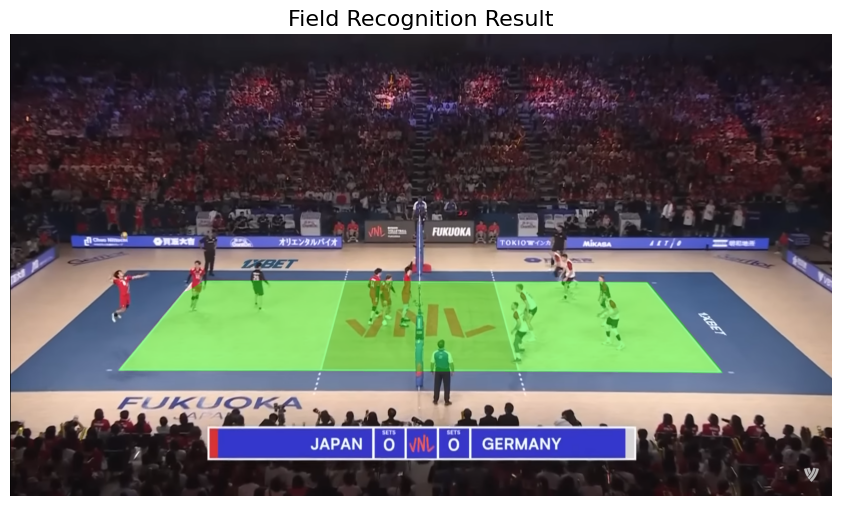

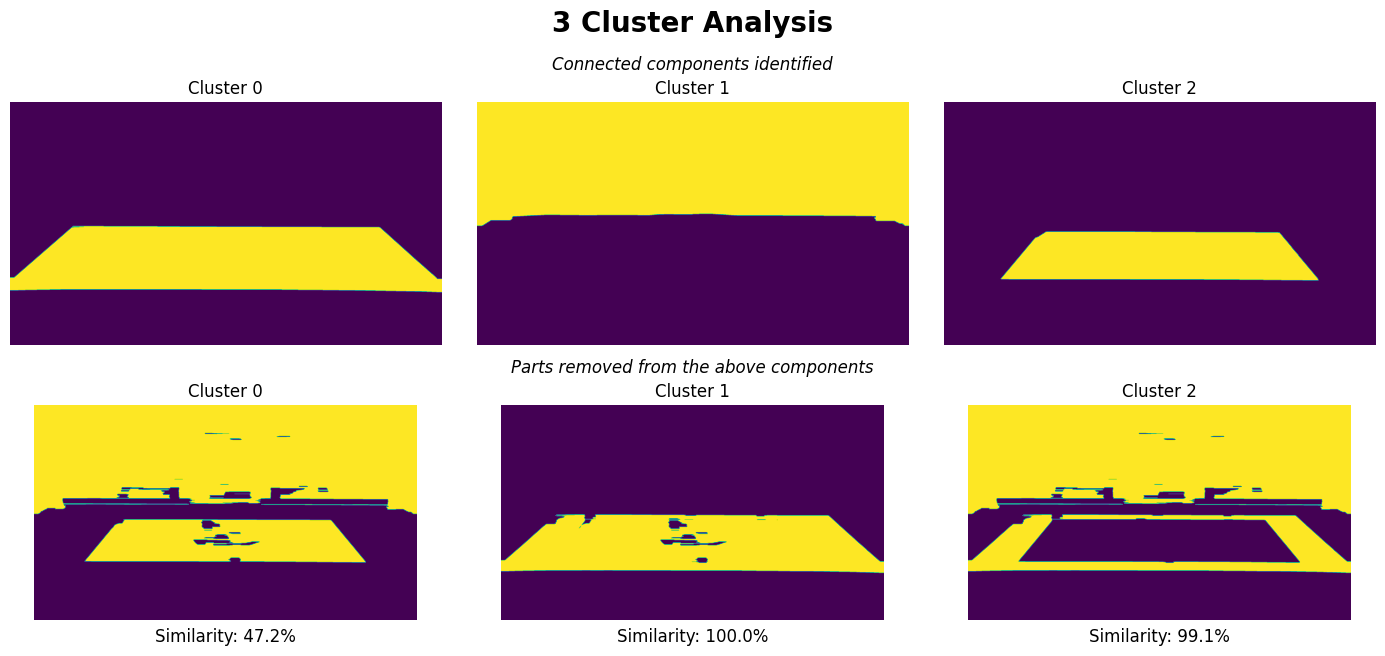

In [140]:
# Create main figure with 2 rows for displaying results
fig, axs = plt.subplots(2, 1, constrained_layout=True, figsize=(14, 6))
fig.suptitle(f'{N_CLUSTERS} Cluster Analysis', fontweight='bold', size=20, y=1.07)  

# Remove the default axes to make room for subfigures
for ax in axs:
  ax.remove()
  
# Get the gridspec from the removed axes to create subfigures
gridspec = axs[0].get_subplotspec().get_gridspec()
subfigs = [fig.add_subfigure(gs) for gs in gridspec]

# Configure the first subfigure for connected components visualization
subfigs[0].suptitle('Connected components identified', fontstyle='italic')
axs_top = subfigs[0].subplots(1, N_CLUSTERS)

# Display filled components
for i in range(N_CLUSTERS):
  axs_top[i].imshow(filled_components[i])
  axs_top[i].set_title(f'Cluster {i}')
  axs_top[i].axis('off')

# Configure the second subfigure for removed parts visualization
subfigs[1].suptitle('Parts removed from the above components', fontstyle='italic')
axs_bottom = subfigs[1].subplots(1, N_CLUSTERS)

# Calculate similarities for each cluster and display removed parts
for i in range(N_CLUSTERS):
  filled = filled_components[i]
  
  # Display removed parts
  axs_bottom[i].imshow(to_removes[i])
  axs_bottom[i].set_title(f'Cluster {i}')
  axs_bottom[i].axis('off')
  axs_bottom[i].text(0.5, -0.1, f'Similarity: {int(similarities[i] * 1000) / 10}%', 
             transform=axs_bottom[i].transAxes, ha='center', fontsize=12)

# Create the field visualization with green overlay
overlay = np.zeros_like(original_rgb, dtype=np.uint8)
overlay[:] = (0, 255, 0)  # Pure green

# Alpha blend the green overlay with the original image
alpha = 0.4  # 0 = transparent, 1 = solid green
blended = cv2.addWeighted(original_rgb, 1 - alpha, overlay, alpha, 0)

# Apply the final mask to show only the field area
output = np.where(final_mask[:, :, np.newaxis] == 255, blended, original_rgb)

# Create and display the result figure
res_fig, res_ax = plt.subplots(1, 1, figsize=(14, 6))
res_ax.imshow(output)
res_ax.set_title('Field Recognition Result', fontsize=16)
res_ax.axis('off')

# Collect all figures for display
figures = [res_fig, fig]

# Display and close figures to free memory
for figure in figures:
  display(figure)
  plt.close(figure)

# Net Recognition

Starting from the court area we've identified, we create an extended region that focuses on the volleyball court while including the net detection area. Since the volleyball net extends vertically above the court surface level, we expand the region upward by half the court height to ensure the complete net structure is captured in our subsequent analysis.

**Region Extension Process:**
- **Vertical Bounds Detection**: Identify the top and bottom boundaries of the detected court area
- **Height Calculation**: Measure the court region height (y_max - y_min)
- **Upward Extension**: Extend the region above the court by 50% of the court height
- **Mask Creation**: Generate a binary mask encompassing both the original court and the extended area above

This strategic extension ensures comprehensive coverage of the net area, which is critical for accurate net detection using vertical line analysis. The 50% extension ratio provides sufficient margin to capture nets of varying heights while maintaining computational efficiency by avoiding unnecessary image area processing.

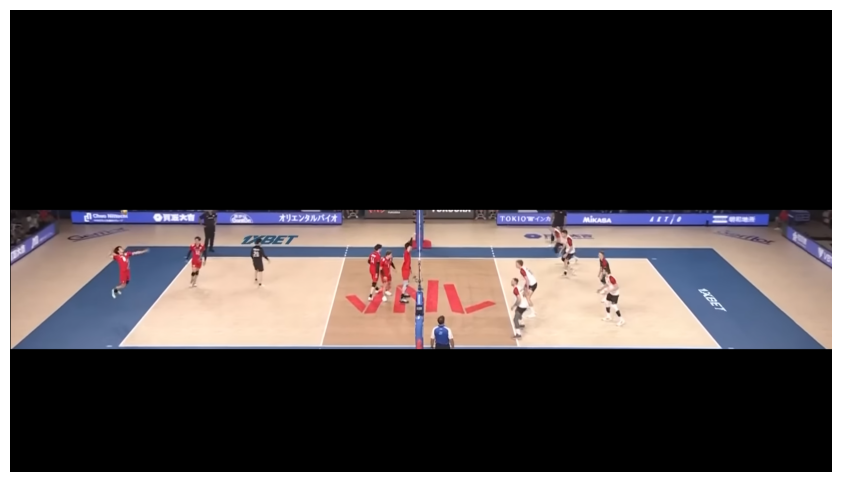

In [141]:
# Create a new empty mask with the same dimensions as final_mask
extended_mask = np.zeros_like(final_mask)

# Find the vertical bounds (y_min, y_max) of the court region in final_mask
ys, xs = np.where(final_mask > 0)
if len(ys) > 0:
    y_min = ys.min()  # Top edge of the court
    y_max = ys.max()  # Bottom edge of the court
    h_region = y_max - y_min + 1  # Height of the court region
    
    # Calculate the new extended y_min by moving upward by half the court height
    # This extends the region above the court to capture the net area
    new_y_min = max(0, int(y_min - h_region / 2))
    
    # Set the extended region to white (255) to create the mask
    # This fills from the new extended top to the original court top
    extended_mask[new_y_min:y_min, :] = 255
    
    # Also include the original court area in the extended mask
    extended_mask[y_min:y_max+1, :] = 255

# Convert the grayscale mask to a 3-channel color mask for bitwise operations
extended_mask = cv2.cvtColor(extended_mask, cv2.COLOR_GRAY2BGR)

# Apply the extended mask to the original image to isolate the court and net area
masked_image = cv2.bitwise_and(original_rgb, extended_mask)

# Display the masked image showing the court with extended area above for net detection
plt.imshow(masked_image)
plt.axis('off')
plt.show()

Next, we identify the volleyball net within the extended court region. To accomplish this, we apply edge detection followed by the Probabilistic Hough Line Transform to detect all potential line segments, then filter them using strict geometric and positional criteria to isolate the net structure.

**Filtering Criteria:**
- **Angle Constraint**: Retain only near-vertical lines (80° to 100° from horizontal)
- **Spatial Constraint**: Exclude lines whose center is within 50 px of the left or right edge to avoid court perimeter detection
- **Length Selection**: Identify the longest qualifying vertical segment, which typically corresponds to the net structure

This approach effectively distinguishes the volleyball net from other vertical elements such as poles, equipment, or court markings by leveraging both geometric properties and spatial positioning within the court area.

Net line coordinates: [[1270  964]
 [1276  624]], Length: 340.05293705539435


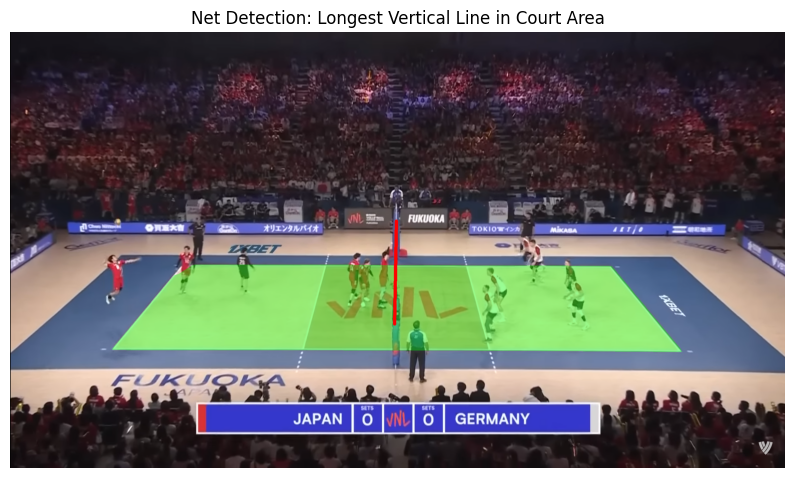

In [142]:
# Step 1: Preprocess the image for edge detection
gray = cv2.cvtColor(masked_image, cv2.COLOR_RGB2GRAY)  # Convert masked court region to grayscale
edges = cv2.Canny(gray, 50, 150)  # Apply Canny edge detection to identify potential line segments

# Step 2: Detect line segments using Probabilistic Hough Line Transform
# Parameters: rho=1 (distance resolution), theta=π/180 (angle resolution in radians),
# threshold=100 (minimum votes), minLineLength=120 (minimum line length),
# maxLineGap=1000 (maximum gap between line segments to connect them)
all_lines = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=100, minLineLength=120, maxLineGap=1000)

# Create an empty image to visualize detected vertical lines
vertical_lines_img = np.zeros_like(edges)

# Step 3: Create overlay image for visualization
overlay = output.copy()  # Copy the field recognition result as base for visualization

# Step 4: Filter detected lines to identify near-vertical lines representing the net
lines = []
W = original_rgb.shape[1]  # Image width for boundary checking

# Filter lines based on angle and position constraints
if all_lines is not None:
    for line in all_lines:
        x1, y1, x2, y2 = line[0]
        # Calculate line angle in degrees (0° = horizontal, 90° = vertical)
        angle = abs(np.degrees(np.arctan2(y2 - y1, x2 - x1)))
        
        # Filter criteria:
        # - Near-vertical: angle between 80° and 100°
        # - Not at image edges: line center must be more than 50px from the left and right edges
        # This ensures we capture the net (vertical) while excluding court boundary lines
        if 80 < angle < 100 and (x1 + x2) > 100 and (2 * W - (x1 + x2)) > 100:
            p1 = np.array([x1, y1])  # Start point
            p2 = np.array([x2, y2])  # End point
            l = np.array([p1, p2])   # Line segment as point pair
            lines.append(l)

# Step 5: Calculate lengths of all detected vertical line segments
def line_length(line):
    """Calculate the Euclidean length of a line segment"""
    diffs = np.diff(line, axis=0)  # Calculate point differences
    segment_lengths = np.linalg.norm(diffs, axis=1)  # Euclidean distance
    return np.sum(segment_lengths)  # Total length (for multi-segment lines)

lengths = [line_length(line) for line in lines]

# Step 6: Identify the longest vertical line as the volleyball net
# Check if any vertical lines were found
if len(lines) > 0:
    # The net typically appears as the longest continuous vertical structure in the court area
    longest_index = np.argmax(lengths)
    longest_line = lines[longest_index]
    longest_length = lengths[longest_index]

    print(f"Net line coordinates: {longest_line}, Length: {longest_length}")

    # Draw the detected net line on the overlay image with a thick red line (the image is RGB, so (255, 0, 0) is red)
    cv2.line(overlay, longest_line[0], longest_line[1], (255, 0, 0), 10)
    
    title = 'Net Detection: Longest Vertical Line in Court Area'
else:
    print("No vertical lines found in the court area. Consider adjusting the filter criteria.")
    title = 'Net Detection: No Vertical Lines Found'

# Step 7: Visualize the net detection result
plt.figure(figsize=(10, 6))
plt.imshow(overlay)
plt.title(title)
plt.axis('off')
plt.show()

# Referee Area Recognition

Finally, having determined the net's position and length, we define the referee area by creating a rectangular region above the net with dimensions proportional to the net length. This approach ensures the referee detection area scales appropriately with the court size and camera perspective.

**Referee Area Parameters:**
- **Width**: Half the net length (`net_length / 2`) to capture the referee's typical lateral movement range during officiating
- **Height**: Two-thirds of the net length (`net_length / 1.5`) to provide adequate vertical coverage for referee positioning
- **Position**: Directly above the net's top point, extending upward to cover the standard referee observation zone

**Rationale for Proportional Sizing:**
The proportional dimensions are based on volleyball officiating standards where referees typically position themselves:
- **Laterally**: Within arm's reach of the net center for optimal line-of-sight
- **Vertically**: At eye level above the net to observe player actions and ball trajectory
- **Coverage Area**: Sufficient space to account for normal referee movement during play

This adaptive sizing approach ensures robust referee area detection across different court perspectives, camera distances, and venue configurations, making the system suitable for various volleyball broadcasting scenarios.

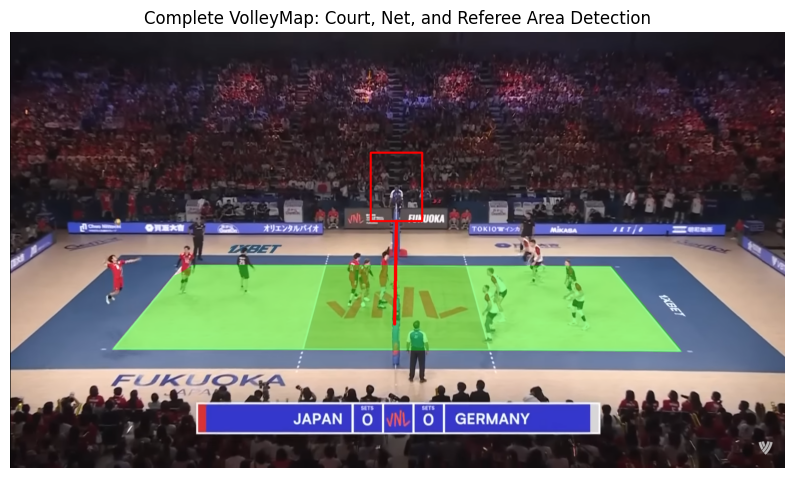

In [143]:
# Get the top point of the detected net line (point with smaller y-coordinate)
top_pixel = longest_line[0] if longest_line[0][1] < longest_line[1][1] else longest_line[1]
# print(f"Top pixel coordinates: {top_pixel}")

# Define the referee area dimensions based on the net length
# Width: half the net length to capture the referee's lateral movement range
rect_width = int(longest_length/2)  
# Height: two-thirds of the net length to provide adequate vertical coverage
rect_height = int(longest_length/1.5)  

# Calculate the referee area rectangle coordinates
# The rectangle is positioned directly above the net's top point
final = overlay.copy()
top_left = (top_pixel[0] - rect_width // 2, top_pixel[1] - rect_height)
bottom_right = (top_pixel[0] + rect_width // 2, top_pixel[1])

# Draw the referee area rectangle in red (RGB) with 5-pixel thickness
cv2.rectangle(final, top_left, bottom_right, (255, 0, 0), 5)

# Visualize the final result showing the court, net, and referee area
plt.figure(figsize=(10, 6))
plt.imshow(final)
plt.title('Complete VolleyMap: Court, Net, and Referee Area Detection')
plt.axis('off')
plt.show()

# Conclusions

Our approach represents an AI-free processing pipeline for detecting different relevant components of volleyball games using traditional computer vision techniques. By relying exclusively on signal processing methods we achieve interpretable and computationally efficient results without requiring training data or neural network models.

## Limitations and Adaptability

Since our methodology uses only traditional signal processing methods, the system doesn't generalize automatically to every type of court configuration, lighting condition, or camera perspective. The approach is particularly sensitive to:
- **Color composition**: Different court surface colors and surrounding area variations
- **Lighting conditions**: Indoor vs. outdoor lighting, shadows, and brightness variations  
- **Camera positioning**: Viewing angle, distance, and perspective distortions

## Parameter Customization

However, we find it very straightforward to adapt the system to different venues by adjusting the key parameters discussed throughout this document:
- **N_CLUSTERS**: Modify based on the court's color complexity (2-4 clusters typically)
- **Saturation enhancement factor**: Adjust the 2.0 multiplier for different lighting conditions
- **Morphological kernel sizes**: Tune the 151×1 and 50×1 kernels for different court scales
- **Hough transform parameters**: Modify thresholds and length constraints for varying net visibility
- **Expected court center**: Adjust the (W/2, 2H/3) position based on camera setup

This parametric approach makes the system highly adaptable to specific volleyball broadcasting scenarios while maintaining the benefits of interpretable, non-black-box processing. The modular design also allows individual components (court detection, net recognition) to be used independently for other volleyball analytics applications.